# The height experiment run to convergence

Stage 2 trained its five-output 1-D U-Net with a cap of 150 epochs, and every seed hit the cap, so its errors were lower bounds on what the architecture can do. This notebook removes the cap: the same model, trained with Stage 1's early stopping to convergence (patience 15, learning rate halved after 6 epochs without improvement, up to 300 epochs, a 45-minute cap as a safety net), on the same splits.

- **Part (a): the later-snapshots split.** One five-output U-Net (targets y+ = 5, 10, 15, 30 and the channel centre; Stage 1's architecture with five output channels), seed 0, and seeds 1 and 2 as well if a training takes under 15 minutes. Error per height as RMSE over the target's spread, against ridge regression on the sign-corrected wall gradient, the first-order wall law and the training mean, and against Stage 2's 150-epoch numbers.
- **Part (b): the spanwise-plane split**, seed 0, for the y+ = 30 case where ridge beat every U-Net seed of Stage 2.

Same samples, splits, normalisation and references as Stage 2 (its code copied below). Every network of this set trains faster on the CPU, so the GPU is hidden. A difference is called an effect only when it is larger than the seed range; a result from one training is labelled as a single run.

# Stage 3 — The height experiment run to convergence

**Portfolio project: from wall shear stress to near-wall velocity, a 1-D U-Net held to honest baselines.**

Stage 2 capped its nine U-Net trainings at 150 epochs and every one of them hit the cap, so its errors were lower bounds on what the architecture can do. Here I remove that cap: the same five-output U-Net (y+ = 5, 10, 15, 30 and the channel centre), the same splits, references and scoring, trained with Stage 1's early stopping (patience 15, learning rate halved after 6 epochs without improvement) up to Stage 1's own limit of 300 epochs, with a 45-minute cap as a safety net. Part (a) is the later-snapshots split; part (b) the spanwise-plane split, for the y+ = 30 case where ridge beat every Stage 2 seed.

**What it shows.** Neither training converged by the early-stopping criterion: both hit the 300-epoch cap with the early-stopping loss still falling slowly (0.365 at epoch 150 to 0.351 at 300 on the later-snapshots split) and the learning rate at its floor. And the longer training did not help where it counts: on later snapshots the error at y+ = 15 (0.638) and 30 (1.001) lies above the whole three-seed range of the 150-epoch models (0.576–0.633 and 0.878–0.989), while y+ = 5 and 10 stay inside it; on held-out planes at y+ = 30 ridge (0.927) still beats the U-Net (0.968, worse than the 150-epoch range 0.946–0.952). The U-Net still beats ridge at y+ = 5, 10 and 15 and is now worse than ridge at 30. Each training took 21–23 minutes, over my 15-minute limit for seed repeats, so these are single runs and the strongest claim is "outside the Stage 2 seed range", not an effect with its own spread.

**How it connects.** It reads the planes from `../release_assets/u_yx_planes_h5/`, copies the wall gradient, y+ and the 1-D U-Net of Stage 1 and the splits, references and scoring of Stage 2, and reads Stage 2's summary table and device timings for the comparison.

**About the outputs.** The outputs below come from my single run (Apple M3 Max, CPU, 2026-10-14, 44 minutes; one training per split). Afterwards I changed only text for this repository: this cell and the paths cell, and the path lines (planes from `../release_assets/`, Stage 2 tables from `../results/02_height_and_generalisation/`, tables, figures and histories to `../results/03_height_run_to_convergence/`, the two seed-0 models to `../models/03_height_run_to_convergence/`). The legends and titles of the two figures say "early stopping" and "converged" although both trainings hit the epoch cap; the tables above them say "epoch cap".

In [ ]:
# Paths in the repository layout (run this notebook from notebooks/)
from pathlib import Path
DATA_DIR = Path("../release_assets/u_yx_planes_h5")                 # the 5,777 planes, from the unet-turbulent-fields release (README)
TIMING_DIR = Path("../results/02_height_and_generalisation")        # device_timing_cpu.csv, device_timing_gpu.csv
EARLIER_STAGE = Path("../results/02_height_and_generalisation")     # Stage 2's tables (read only for the comparison)
RES = Path("../results/03_height_run_to_convergence"); RES.mkdir(parents=True, exist_ok=True)
MOD = Path("../models/03_height_run_to_convergence"); MOD.mkdir(parents=True, exist_ok=True)
print("planes:", len(sorted(DATA_DIR.glob("P125_83pi.*.h5"))), "| timings present:", (TIMING_DIR / "device_timing_cpu.csv").exists(), "| Stage 2 tables present:", (EARLIER_STAGE / "summary.csv").exists())

In [2]:
import json, re, time, platform
import h5py
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split

# Device from the step timing of Stage 2 (one training step inside model.fit, batch 32, median of 30 after 10 warm-up);
# the environment is unchanged since then
timing = pd.concat([pd.read_csv(TIMING_DIR / "device_timing_cpu.csv"), pd.read_csv(TIMING_DIR / "device_timing_gpu.csv")])
tt = timing.pivot(index="network", columns="device", values="median_ms"); print(tt.round(2))
row = [r for r in tt.index if "5 outputs" in r][0]; assert tt.loc[row, "cpu"] < tt.loc[row, "gpu"]
tf.config.set_visible_devices([], "GPU"); DEVICE = "/CPU:0"
print("TensorFlow", tf.__version__, "| Keras", tf.keras.__version__, "| visible GPUs:", tf.config.get_visible_devices("GPU"), "|", platform.machine(), "| device:", DEVICE)
T_START = time.time()

device                                     cpu    gpu
network                                              
1-D U-Net, 16 filters, 2 outputs         15.60  81.17
1-D U-Net, 16 filters, 5 outputs (Ex 1)  15.55  88.82
1-D U-Net, 32 filters (Ex 3)             39.58  94.02
single conv block (Ex 5)                  1.31   6.22
small dense network (Ex 5)                0.74   4.47
TensorFlow 2.18.1 | Keras 3.6.0 | visible GPUs: [] | arm64 | device: /CPU:0


## Data: the wall gradient at both walls and u at five heights

Copied from Stage 2: the wall gradient by Stage 1's second-order one-sided difference at both walls, the targets at y+ = 5, 10, 15, 30 and 125 (the channel centre, nominal friction Reynolds number 125), and the first-order wall law u = (du/dy)_wall · (y − y_wall) as a reference. Each plane gives two samples, one per wall: 11,554 samples of 384 wall values → 384 × 5 target values.

In [3]:
# Copied unchanged from Stage 2 (Stage 1's wall gradient and y+)
def wall_gradient(u_wall_to_inner, y_wall_to_inner):
    h1 = y_wall_to_inner[1] - y_wall_to_inner[0]
    h2 = y_wall_to_inner[2] - y_wall_to_inner[1]
    c0 = -(2 * h1 + h2) / (h1 * (h1 + h2)); c1 = (h1 + h2) / (h1 * h2); c2 = -h1 / (h2 * (h1 + h2))
    return c0 * u_wall_to_inner[0] + c1 * u_wall_to_inner[1] + c2 * u_wall_to_inner[2]

def compute_tau_w_both_walls(u, y):
    return wall_gradient(u[0:3, :], y[0:3]), wall_gradient(u[-1:-4:-1, :], y[-1:-4:-1])

files = sorted(DATA_DIR.glob("P125_83pi.*.h5"))
with h5py.File(files[0], "r") as f: y0 = f["y"][:]
half_height = (y0[-1] - y0[0]) / 2.0; RE_TAU = 125.0
YP = [5.0, 10.0, 15.0, 30.0, 125.0]
yp_b = (y0 - y0[0]) / half_height * RE_TAU; yp_t = (y0[-1] - y0) / half_height * RE_TAU
idx_b = [int(np.argmin(np.abs(yp_b - t))) for t in YP]; idx_t = [int(np.argmin(np.abs(yp_t - t))) for t in YP]
for t, ib, it in zip(YP, idx_b, idx_t):
    print(f"y+ target {t:6.1f}: bottom index {ib:3d} (y+ {yp_b[ib]:6.2f}), top index {it:3d} (y+ {yp_t[it]:6.2f})")

X, Y, LIN, snap, zpl, wall = [], [], [], [], [], []
t0 = time.time()
for f_ in files:
    with h5py.File(f_, "r") as f: u = f["u"][:]; y = f["y"][:]
    assert np.array_equal(y, y0)
    tb, tt_ = compute_tau_w_both_walls(u, y)
    s_, z_ = (int(v) for v in re.search(r"\.(\d+)\.(\d+)\.h5$", f_.name).groups())
    for w_, tau, idx, yw in (("bottom", tb, idx_b, y0[0]), ("top", tt_, idx_t, y0[-1])):
        X.append(tau); Y.append(np.stack([u[i] for i in idx], -1))
        LIN.append(np.stack([tau * (y0[i] - yw) for i in idx], -1))
        snap.append(s_); zpl.append(z_); wall.append(w_)
X = np.array(X, np.float32)[..., None]; Y = np.array(Y, np.float32); LIN = np.array(LIN, np.float32)
snap, zpl, wall = np.array(snap), np.array(zpl), np.array(wall)
print(f"samples {X.shape} -> {Y.shape} in {time.time() - t0:.0f} s; {len(np.unique(snap))} snapshots, {len(np.unique(zpl))} spanwise planes")

y+ target    5.0: bottom index  10 (y+   4.92), top index 190 (y+   4.92)
y+ target   10.0: bottom index  17 (y+  10.08), top index 183 (y+  10.08)
y+ target   15.0: bottom index  23 (y+  15.43), top index 177 (y+  15.43)
y+ target   30.0: bottom index  36 (y+  29.46), top index 164 (y+  29.46)
y+ target  125.0: bottom index 100 (y+ 125.00), top index 100 (y+ 125.00)


samples (11554, 384, 1) -> (11554, 384, 5) in 12 s; 107 snapshots, 60 spanwise planes


## The two splits, the references and the U-Net

Copied from Stage 2. **Later-snapshots split**: the last 20 % of snapshot numbers are held out with all their planes and both walls. **Spanwise-plane split**: the planes labelled 48, 49 and 80 to 89 are held out at every time. In each, 15 % of the training samples (the same random draw) are set aside for early stopping and for choosing the ridge penalty; normalisation statistics come from the fitting part only. References: the training mean, the first-order wall law, and ridge regression from the 384 wall values (the gradient taken into the fluid at both walls, so the top-wall input is sign-corrected) to the 384 × 5 normalised targets, with the penalty chosen on the early-stopping part. The U-Net is Stage 1's 1-D U-Net with 16 base filters, four levels and five output channels (677,000 weights), Adam at 1e-4 with gradient clipping 1, mean squared error, batch 32. Scores per height: MAE, RMSE, and RMSE divided by the target's spread over the test samples (1 = the mean predictor).

In [4]:
ALL = np.arange(len(X))
snaps = np.unique(snap); cut = snaps[int(np.floor(0.8 * len(snaps)))]
tr_t, te_t = ALL[snap < cut], ALL[snap >= cut]
tr_p, te_p = ALL[zpl < 48], ALL[zpl >= 48]
SPLITS = {"time (later snapshots held out)": (tr_t, te_t), "planes (spanwise planes 48-49 and 80-89 held out)": (tr_p, te_p)}
for k, (a_, b_) in SPLITS.items():
    print(f"{k:50s} train {len(a_):5d}  test {len(b_):5d}  shared snapshots {len(set(snap[a_]) & set(snap[b_])):3d}  shared planes {len(set(zpl[a_]) & set(zpl[b_])):3d}")

# Stage 1's 1-D U-Net, copied unchanged
def conv_block(x, filters, kernel_size=3, activation="relu", padding="same", dropout_rate=0.0):
    x = tf.keras.layers.Conv1D(filters, kernel_size, activation=activation, padding=padding, kernel_initializer="he_normal")(x)
    x = tf.keras.layers.Conv1D(filters, kernel_size, activation=activation, padding=padding, kernel_initializer="he_normal")(x)
    if dropout_rate > 0.0: x = tf.keras.layers.Dropout(dropout_rate)(x)
    return x
def encoder_block(x, filters, dropout_rate=0.0):
    skip = conv_block(x, filters, dropout_rate=dropout_rate); return skip, tf.keras.layers.MaxPooling1D(pool_size=2)(skip)
def decoder_block(x, skip, filters, dropout_rate=0.0):
    x = tf.keras.layers.Conv1DTranspose(filters, kernel_size=2, strides=2, padding="same")(x)
    return conv_block(tf.keras.layers.Concatenate()([x, skip]), filters, dropout_rate=dropout_rate)
def create_unet_wall_to_nearwall(input_shape, output_channels, base_filters=16, dropout_rate=0.0, learning_rate=1e-4):
    inputs = tf.keras.layers.Input(shape=input_shape)
    skip1, x = encoder_block(inputs, base_filters, dropout_rate); skip2, x = encoder_block(x, base_filters * 2, dropout_rate)
    skip3, x = encoder_block(x, base_filters * 4, dropout_rate); skip4, x = encoder_block(x, base_filters * 8, dropout_rate)
    x = conv_block(x, base_filters * 16, dropout_rate=dropout_rate)
    x = decoder_block(x, skip4, base_filters * 8, dropout_rate); x = decoder_block(x, skip3, base_filters * 4, dropout_rate)
    x = decoder_block(x, skip2, base_filters * 2, dropout_rate); x = decoder_block(x, skip1, base_filters, dropout_rate)
    outputs = tf.keras.layers.Conv1D(output_channels, kernel_size=1, activation="linear")(x)
    model = tf.keras.Model(inputs, outputs, name="UNet1D_WallToNearWall")
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0), loss="mse", metrics=["mae"])
    return model
print("U-Net parameters:", create_unet_wall_to_nearwall((384, 1), len(YP), base_filters=16).count_params())

def scores(pred, truth):
    err = pred - truth
    mae = np.mean(np.abs(err), axis=(0, 1)); rmse = np.sqrt(np.mean(err ** 2, axis=(0, 1))); spread = truth.std(axis=(0, 1))
    return mae, rmse, rmse / spread, spread

rows, prep = [], {}
def add_rows(split, te, model, pred, seed=-1, **extra):
    mae, rmse, nrmse, spread = scores(pred, Y[te])
    for j, yp in enumerate(YP):
        rows.append(dict(split=split, model=model, seed=seed, y_plus=yp, mae=float(mae[j]), rmse=float(rmse[j]), rmse_over_spread=float(nrmse[j]), spread=float(spread[j]), **extra))
for split, (tr, te) in SPLITS.items():
    fit, stop = train_test_split(tr, test_size=0.15, random_state=24, shuffle=True)
    xm, xs = X[fit].mean(), X[fit].std() + 1e-8; ym, ys = Y[fit].mean(axis=(0, 1)), Y[fit].std(axis=(0, 1)) + 1e-8
    prep[split] = (fit, stop, te, xm, xs, ym, ys)
    add_rows(split, te, "training mean", np.broadcast_to(Y[fit].mean(axis=(0, 1)), Y[te].shape))
    add_rows(split, te, "viscous-sublayer linear law", LIN[te])
    XR = X[..., 0] * np.where(wall == "top", -1.0, 1.0)[:, None]; rm, rs = XR[fit].mean(), XR[fit].std() + 1e-8
    Xf, Xs_, Xt_ = [((XR[i] - rm) / rs) for i in (fit, stop, te)]
    Yf, Ys_ = [((Y[i] - ym) / ys).reshape(len(i), -1) for i in (fit, stop)]
    best = min(((a_, np.mean((Ridge(alpha=a_).fit(Xf, Yf).predict(Xs_) - Ys_) ** 2)) for a_ in (1e-2, 1e-1, 1, 10, 100, 1e3, 1e4)), key=lambda t: t[1])
    rg = Ridge(alpha=best[0]).fit(np.vstack([Xf, Xs_]), np.vstack([Yf, Ys_]))
    add_rows(split, te, "ridge", rg.predict(Xt_).reshape(len(te), 384, len(YP)) * ys + ym, alpha=best[0])
    print(split, "| ridge alpha", best[0])

time (later snapshots held out)                    train  9298  test  2256  shared snapshots   0  shared planes  60
planes (spanwise planes 48-49 and 80-89 held out)  train 10272  test  1282  shared snapshots 107  shared planes   0
U-Net parameters: 677173


time (later snapshots held out) | ridge alpha 0.1


planes (spanwise planes 48-49 and 80-89 held out) | ridge alpha 0.1


## Training to convergence

Stage 1's callbacks: early stopping on the early-stopping loss with patience 15 (best weights restored) and learning-rate halving after 6 epochs without improvement, up to 300 epochs. A 45-minute cap stops a training that has not converged by then and is recorded as such. Each training prints its epochs, the epoch of its best early-stopping loss, its wall time and whether it stopped early, hit the epoch cap or hit the time cap.

In [5]:
class TimeCap(tf.keras.callbacks.Callback):
    def __init__(self, minutes): super().__init__(); self.limit = minutes * 60; self.hit = False
    def on_train_begin(self, logs=None): self.t0 = time.time()
    def on_epoch_end(self, epoch, logs=None):
        if time.time() - self.t0 > self.limit: self.model.stop_training = True; self.hit = True

train_info = {}
def run_unet(split, seed, max_epochs=300, cap_min=45):
    fit, stop, te, xm, xs, ym, ys = prep[split]
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    m = create_unet_wall_to_nearwall((384, 1), len(YP), base_filters=16); cap = TimeCap(cap_min); t0 = time.time()
    h = m.fit((X[fit] - xm) / xs, (Y[fit] - ym) / ys, validation_data=((X[stop] - xm) / xs, (Y[stop] - ym) / ys), epochs=max_epochs, batch_size=32, verbose=0,
              callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
                         tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-6), cap])
    train_s = time.time() - t0; n_ep = len(h.history["loss"]); best = int(np.argmin(h.history["val_loss"])) + 1
    how = "time cap" if cap.hit else ("epoch cap" if n_ep >= max_epochs else "early stopping")
    pred = m.predict((X[te] - xm) / xs, verbose=0, batch_size=256) * ys + ym
    add_rows(split, te, "1-D U-Net", pred, seed=seed, epochs=n_ep, best_epoch=best, train_s=round(train_s, 1), stopped_by=how, best_val_loss=float(min(h.history["val_loss"])))
    pd.DataFrame(dict(epoch=np.arange(1, n_ep + 1), loss=h.history["loss"], val_loss=h.history["val_loss"], lr=h.history.get("learning_rate", [np.nan] * n_ep))).to_csv(
        RES / f"history_{'time' if split.startswith('time') else 'planes'}_seed{seed}.csv", index=False)
    if seed == 0:
        tag = "time" if split.startswith("time") else "planes"
        m.save(MOD / f"unet1d_five_outputs_{tag}_split_seed0.keras"); np.savez(MOD / f"unet1d_five_outputs_{tag}_split_normalization.npz", xm=xm, xs=xs, ym=ym, ys=ys)
    train_info[(split, seed)] = dict(epochs=n_ep, best_epoch=best, train_s=train_s, stopped_by=how)
    _, _, nrmse, _ = scores(pred, Y[te])
    print(f"seed {seed} | {split} | {n_ep} epochs (best {best}), {train_s / 60:.1f} min, {how} | RMSE/spread per height {np.round(nrmse, 3)}", flush=True)
    return train_s

## Part (a): the later-snapshots split, seed 0, then seeds 1 and 2 if a training is under 15 minutes

In [6]:
TS = "time (later snapshots held out)"
t_seed0 = run_unet(TS, 0)  # seed 0, the base run
REPEAT = t_seed0 < 15 * 60
print("seed-0 training under 15 minutes:", REPEAT, "→", "seeds 1 and 2 follow" if REPEAT else "seeds 1 and 2 are skipped (single run)")

seed 0 | time (later snapshots held out) | 300 epochs (best 300), 20.8 min, epoch cap | RMSE/spread per height [0.191 0.403 0.638 1.001 1.066]


seed-0 training under 15 minutes: False → seeds 1 and 2 are skipped (single run)


In [7]:
if REPEAT: run_unet(TS, 1)  # seed 1
else: print("skipped: the seed-0 training took", round(t_seed0 / 60, 1), "minutes, over the 15-minute limit for repeats")

skipped: the seed-0 training took 20.8 minutes, over the 15-minute limit for repeats


In [8]:
if REPEAT: run_unet(TS, 2)  # seed 2
else: print("skipped: the seed-0 training took", round(t_seed0 / 60, 1), "minutes, over the 15-minute limit for repeats")

skipped: the seed-0 training took 20.8 minutes, over the 15-minute limit for repeats


### Part (a) table and figure

Stage 2's U-Net rows are its three seeds at the 150-epoch cap on the same split and test samples. "Early stopping changes the error beyond the seed range" at a height when this run's range (or single value) and Stage 2's three-seed range do not overlap. The U-Net's advantage over ridge is ridge's error minus the U-Net's, in units of the target's spread.

RMSE / target spread, later-snapshots split (U-Net: single run, seed 0)
model   target spread  1-D U-Net   ridge  viscous-sublayer linear law  training mean  U-Net min  U-Net max  U-Net seeds  Stage 2 150-epoch U-Net  Stage 2 min  Stage 2 max  changes beyond seed range  advantage over ridge, this run  advantage over ridge, Stage 2  beats ridge in every seed
y_plus                                                                                                                                                                                                                                                                                         
5.0            0.0955     0.1914  0.2173                       0.3585         1.0009     0.1914     0.1914            1                   0.1915       0.1883       0.1947                      False                          0.0259                         0.0258                       True
10.0           0.1468     0.4030  0.4808                       1

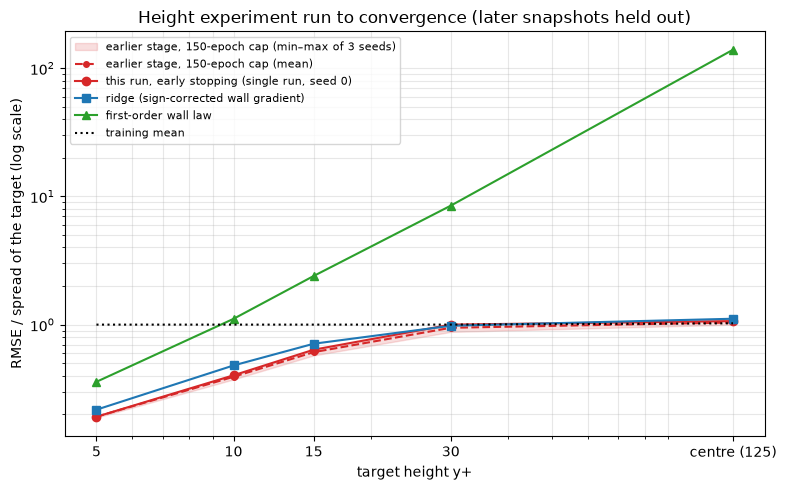

In [9]:
df = pd.DataFrame(rows); df.to_csv(RES / "runs.csv", index=False)
agg = df.groupby(["split", "model", "y_plus"]).agg(mae=("mae", "mean"), r=("rmse_over_spread", "mean"), r_min=("rmse_over_spread", "min"), r_max=("rmse_over_spread", "max"),
                                                  n_seeds=("seed", lambda s: int((s >= 0).sum()) if (s >= 0).any() else 0), spread=("spread", "first")).reset_index()
agg.to_csv(RES / "summary.csv", index=False)
earlier = pd.read_csv(EARLIER_STAGE / "summary.csv")
ea = earlier[(earlier.split == TS) & (earlier.model == "1-D U-Net")].set_index("y_plus")
a = agg[agg.split == TS]
ta = a.pivot(index="y_plus", columns="model", values="r")[["1-D U-Net", "ridge", "viscous-sublayer linear law", "training mean"]].copy()
ta.insert(0, "target spread", a.groupby("y_plus").spread.first())
u = a[a.model == "1-D U-Net"].set_index("y_plus")
ta["U-Net min"], ta["U-Net max"], ta["U-Net seeds"] = u.r_min, u.r_max, u.n_seeds
ta["Stage 2 150-epoch U-Net"], ta["Stage 2 min"], ta["Stage 2 max"] = ea.r, ea.r_min, ea.r_max
ta["changes beyond seed range"] = [(ta.loc[y, "U-Net max"] < ta.loc[y, "Stage 2 min"]) or (ta.loc[y, "U-Net min"] > ta.loc[y, "Stage 2 max"]) for y in ta.index]
ta["advantage over ridge, this run"] = ta["ridge"] - ta["1-D U-Net"]
er = earlier[(earlier.split == TS) & (earlier.model == "ridge")].set_index("y_plus").r
ta["advantage over ridge, Stage 2"] = er - ea.r
ta["beats ridge in every seed"] = [bool(ta.loc[y, "U-Net max"] < ta.loc[y, "ridge"]) for y in ta.index]
ta.to_csv(RES / "a_height_table.csv")
pd.set_option("display.width", 250)
print("RMSE / target spread, later-snapshots split" + (" (U-Net: mean of 3 seeds)" if REPEAT else " (U-Net: single run, seed 0)"))
print(ta.round(4).to_string())
print("\nTraining:", {f"seed {k[1]}": v for k, v in train_info.items() if k[0] == TS})
ch = [f"y+ = {y:g}" for y in ta.index if ta.loc[y, "changes beyond seed range"]]
print(f"\nResult (a): early stopping changes the U-Net's error beyond the seed range at {', '.join(ch) if ch else 'no height'}; "
      f"advantage over ridge (ridge − U-Net, in units of spread) this run / Stage 2: " + ", ".join(f"y+ {y:g}: {ta.loc[y, 'advantage over ridge, this run']:+.3f} / {ta.loc[y, 'advantage over ridge, Stage 2']:+.3f}" for y in ta.index))
if not REPEAT: print("Single run: this run's U-Net value has no seed range of its own; the comparison uses Stage 2's three-seed range only.")

fig, ax = plt.subplots(figsize=(8, 5))
yv = np.array(ta.index)
ax.fill_between(yv, ta["Stage 2 min"], ta["Stage 2 max"], color="#d62728", alpha=0.15, label="Stage 2, 150-epoch cap (min–max of 3 seeds)")
ax.plot(yv, ta["Stage 2 150-epoch U-Net"], color="#d62728", ls="--", marker="o", ms=4, label="Stage 2, 150-epoch cap (mean)")
if REPEAT: ax.errorbar(yv, ta["1-D U-Net"], yerr=[ta["1-D U-Net"] - ta["U-Net min"], ta["U-Net max"] - ta["1-D U-Net"]], color="#d62728", marker="o", capsize=3, label="this run, early stopping (mean, min–max of 3 seeds)")
else: ax.plot(yv, ta["1-D U-Net"], color="#d62728", marker="o", label="this run, early stopping (single run, seed 0)")
ax.plot(yv, ta["ridge"], color="#1f77b4", marker="s", label="ridge (sign-corrected wall gradient)")
ax.plot(yv, ta["viscous-sublayer linear law"], color="#2ca02c", marker="^", label="first-order wall law")
ax.plot(yv, ta["training mean"], color="k", ls=":", label="training mean")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(YP); ax.set_xticklabels(["5", "10", "15", "30", "centre (125)"])
ax.set_xlabel("target height y+"); ax.set_ylabel("RMSE / spread of the target (log scale)"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_title("Height experiment run to convergence (later snapshots held out)"); fig.tight_layout(); fig.savefig(RES / "a_height_converged.png", dpi=130); plt.show()

## Part (b): the spanwise-plane split, seed 0, for the y+ = 30 case

In [10]:
PS = "planes (spanwise planes 48-49 and 80-89 held out)"
run_unet(PS, 0)  # seed 0, single run on the plane split

seed 0 | planes (spanwise planes 48-49 and 80-89 held out) | 300 epochs (best 300), 23.0 min, epoch cap | RMSE/spread per height [0.19  0.397 0.62  0.968 1.102]


1377.4216091632843

RMSE / target spread, spanwise-plane split (this run's U-Net: single run, seed 0; Stage 2: mean of 3 seeds at the 150-epoch cap)
model   1-D U-Net   ridge  viscous-sublayer linear law  training mean  Stage 2 150-epoch U-Net  Stage 2 min  Stage 2 max  Stage 2 ridge
y_plus                                                                                                                                 
5.0        0.1901  0.2057                       0.3638         1.0007                   0.1905       0.1895       0.1924         0.2057
10.0       0.3969  0.4520                       1.1243         1.0008                   0.3939       0.3929       0.3959         0.4520
15.0       0.6202  0.6646                       2.4267         1.0009                   0.6112       0.6102       0.6127         0.6646
30.0       0.9677  0.9272                       8.5947         1.0010                   0.9491       0.9462       0.9524         0.9272
125.0      1.1018  1.0626                     144.3509 

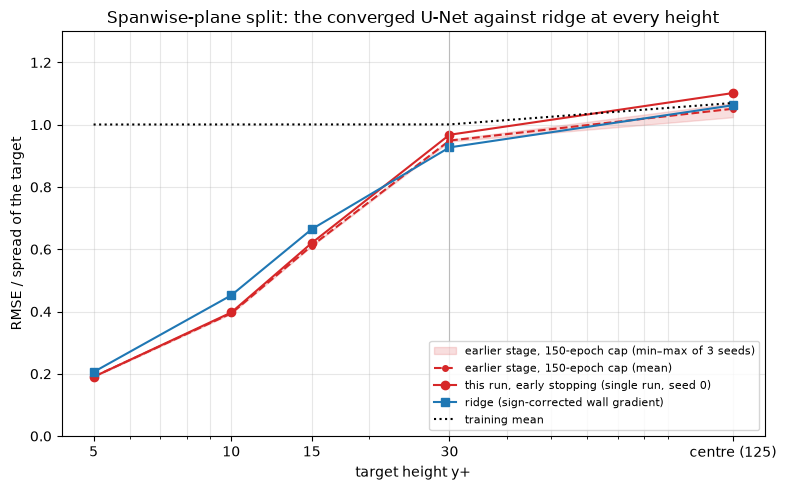

In [11]:
df = pd.DataFrame(rows); df.to_csv(RES / "runs.csv", index=False)
agg = df.groupby(["split", "model", "y_plus"]).agg(mae=("mae", "mean"), r=("rmse_over_spread", "mean"), r_min=("rmse_over_spread", "min"), r_max=("rmse_over_spread", "max"),
                                                  n_seeds=("seed", lambda s: int((s >= 0).sum()) if (s >= 0).any() else 0), spread=("spread", "first")).reset_index()
agg.to_csv(RES / "summary.csv", index=False)
b = agg[agg.split == PS]; eb = earlier[(earlier.split == PS)]
tb = b.pivot(index="y_plus", columns="model", values="r")[["1-D U-Net", "ridge", "viscous-sublayer linear law", "training mean"]].copy()
ebu = eb[eb.model == "1-D U-Net"].set_index("y_plus"); tb["Stage 2 150-epoch U-Net"], tb["Stage 2 min"], tb["Stage 2 max"] = ebu.r, ebu.r_min, ebu.r_max
tb["Stage 2 ridge"] = eb[eb.model == "ridge"].set_index("y_plus").r
tb.to_csv(RES / "b_planes_table.csv")
print("RMSE / target spread, spanwise-plane split (this run's U-Net: single run, seed 0; Stage 2: mean of 3 seeds at the 150-epoch cap)"); print(tb.round(4).to_string())
print("Training:", train_info[(PS, 0)])
r30 = tb.loc[30.0]
print(f"\nResult (b), y+ = 30 on the plane split: U-Net this run {r30['1-D U-Net']:.4f} (single run) vs ridge {r30['ridge']:.4f}; Stage 2 U-Net {r30['Stage 2 150-epoch U-Net']:.4f} "
      f"[{r30['Stage 2 min']:.4f}, {r30['Stage 2 max']:.4f}] vs ridge {r30['Stage 2 ridge']:.4f}. "
      + ("The converged U-Net is below ridge" if r30['1-D U-Net'] < r30['ridge'] else "Ridge still beats the U-Net")
      + ("; outside the Stage 2 three-seed range" if (r30['1-D U-Net'] < r30['Stage 2 min'] or r30['1-D U-Net'] > r30['Stage 2 max']) else "; within the Stage 2 three-seed range") + ".")

fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(tb.index, tb["Stage 2 min"], tb["Stage 2 max"], color="#d62728", alpha=0.15, label="Stage 2, 150-epoch cap (min–max of 3 seeds)")
ax.plot(tb.index, tb["Stage 2 150-epoch U-Net"], color="#d62728", ls="--", marker="o", ms=4, label="Stage 2, 150-epoch cap (mean)")
ax.plot(tb.index, tb["1-D U-Net"], color="#d62728", marker="o", label="this run, early stopping (single run, seed 0)")
ax.plot(tb.index, tb["ridge"], color="#1f77b4", marker="s", label="ridge (sign-corrected wall gradient)")
ax.plot(tb.index, tb["training mean"], color="k", ls=":", label="training mean")
ax.axvline(30, color="#bbb", lw=0.8)
ax.set_xscale("log"); ax.set_xticks(YP); ax.set_xticklabels(["5", "10", "15", "30", "centre (125)"]); ax.set_ylim(0, 1.3)
ax.set_xlabel("target height y+"); ax.set_ylabel("RMSE / spread of the target"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_title("Spanwise-plane split: the converged U-Net against ridge at every height"); fig.tight_layout(); fig.savefig(RES / "b_planes_converged.png", dpi=130); plt.show()

## Record of the run

In [12]:
summary = dict(samples=int(len(X)), splits={k: dict(train=int(len(a_)), test=int(len(b_))) for k, (a_, b_) in SPLITS.items()}, device=DEVICE, repeat_seeds=bool(REPEAT),
               training={f"{k[0]} | seed {k[1]}": v for k, v in train_info.items()}, part_a=ta.reset_index().to_dict("records"), part_b=tb.reset_index().to_dict("records"),
               longest_training_min=float(max(v["train_s"] for v in train_info.values()) / 60), wall_min=round((time.time() - T_START) / 60, 1), tensorflow=tf.__version__, keras=tf.keras.__version__)
json.dump(summary, open(RES / "run_summary.json", "w"), indent=1, default=float)
print(f"longest single training {summary['longest_training_min']:.1f} min; notebook wall time {summary['wall_min']:.1f} min")

longest single training 23.0 min; notebook wall time 44.0 min
